In [1]:
from Functions import *
from Rewiring_functions import *

In [2]:
Ilist=read_database()
#create a dictionary with the matrix of each site-eachyear
networks={}
for site in Sites:
    #print(site)
    networks[site]={}
    for year in Years:
        Imat = Ilist.xs((site,year),level=["Site_ID", "Year"]).pivot(index="Plant_gen_sp",columns="Pollinator_gen_sp",values="Frequency").fillna(0)
        networks[site][year]=Imat


In [3]:
#hay que elegir sitio y año!
site=Sites[0] #2,1/9.3/10/6 /0.4
year=Years[0]#4
web1=networks[site][year]
web2=networks[site][year+1]

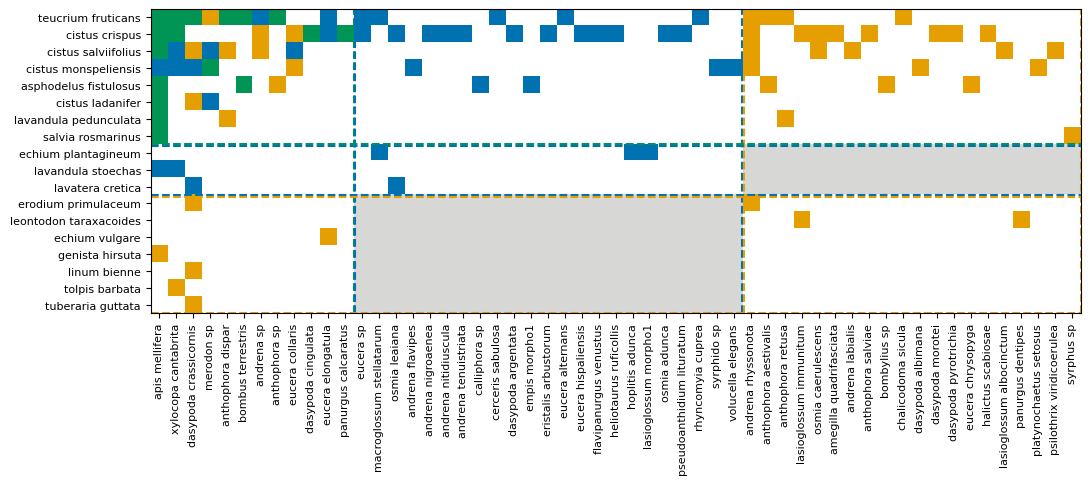

In [4]:
#La identificación la tenemos que hacer en la red NO pesada, que nos permite sabes cuales son las especies permanente sy cuales no
plt.rcParams.update({'font.size': 15})
# Create a figure
fig, ax1 = plt.subplots(figsize=(12, 8))
#plot_betadiversity_matrix_to_ax(web1/web1,web2/web2,ax=ax1)
plot_betadiversity_Wmatrix_to_ax(web1,web2,ax=ax1,weighted=False,names=True)
plt.show()

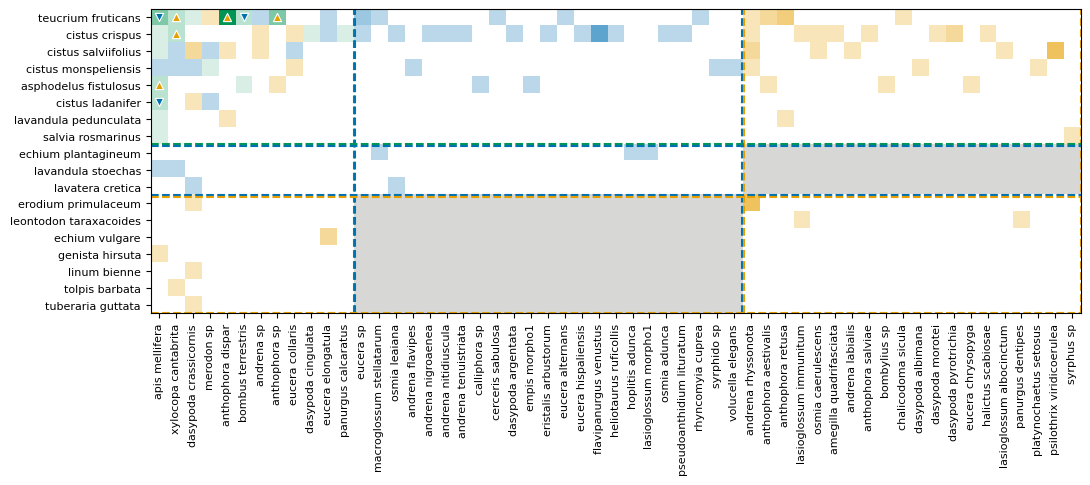

In [5]:
fig, ax1 = plt.subplots(figsize=(12, 8))
plot_betadiversity_Wmatrix_to_ax(web1,web2,ax=ax1,names=True)
plt.show()

# quantification of changes

In [18]:
# We store the databases with 1 to 4 time lag
#Generamos los diccionaros con las 4 dataframes
metric=['CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']
metric_N=["PA","PP","A1","P1","A2","P2"]
mi2=pd.MultiIndex.from_product([Sites,Years[1::],metric],names=["Site_ID", "year","metric"])
mi2N=pd.MultiIndex.from_product([Sites,Years[1::],metric_N],names=["Site_ID", "year","metric"])
All_Changes={}
All_Nodes={}
for N in range(1,5):
    Changes_df=pd.DataFrame(index=mi2,columns=["n_interactions","freq_interactions"])
    Changes_df.sort_index(inplace=True)
    
    Nodes_df=pd.DataFrame(index=mi2N,columns=["n_nodes"])
    Nodes_df.sort_index(inplace=True)
    
    for site in Sites:
        for year in Years[0:-N]:
            changes, nodes = rewiring_freq_py(networks[site][year], networks[site][year+N])
            changes = changes.set_index('metric')          # <- AÑADIR esto
            nodes = nodes.set_index('metric')          # <- AÑADIR esto
            for m in changes.index:                        # <- 'm', NO 'metric'
                Changes_df.loc[(site, year+N, m), 'n_interactions'] = changes.loc[m, 'n_interactions']
                Changes_df.loc[(site, year+N, m), 'freq_interactions'] = changes.loc[m, 'freq_sum']
            for m in nodes.index:                        # <- 'm', NO 'metric'
                Nodes_df.loc[(site, year+N, m), 'n_nodes'] = nodes.loc[m, 'n_species']
        Changes_df['n_interactions'] = Changes_df['n_interactions'].astype('float64')
        Changes_df['freq_interactions'] = Changes_df['freq_interactions'].astype('float64')
    All_Changes[N]=Changes_df
    All_Nodes[N]=Nodes_df
  

# Average descritpion trough time, for one site

In [19]:
Changes_df=All_Changes[1]
Nodes_df=All_Nodes[1]

/home/vir/ownCloud - Virginia Domínguez@gloton.ugr.es/Trabajo/colaboraciones/Rewiring Alfonso/Rwiring_manuscript_code/Functions.py:2239: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


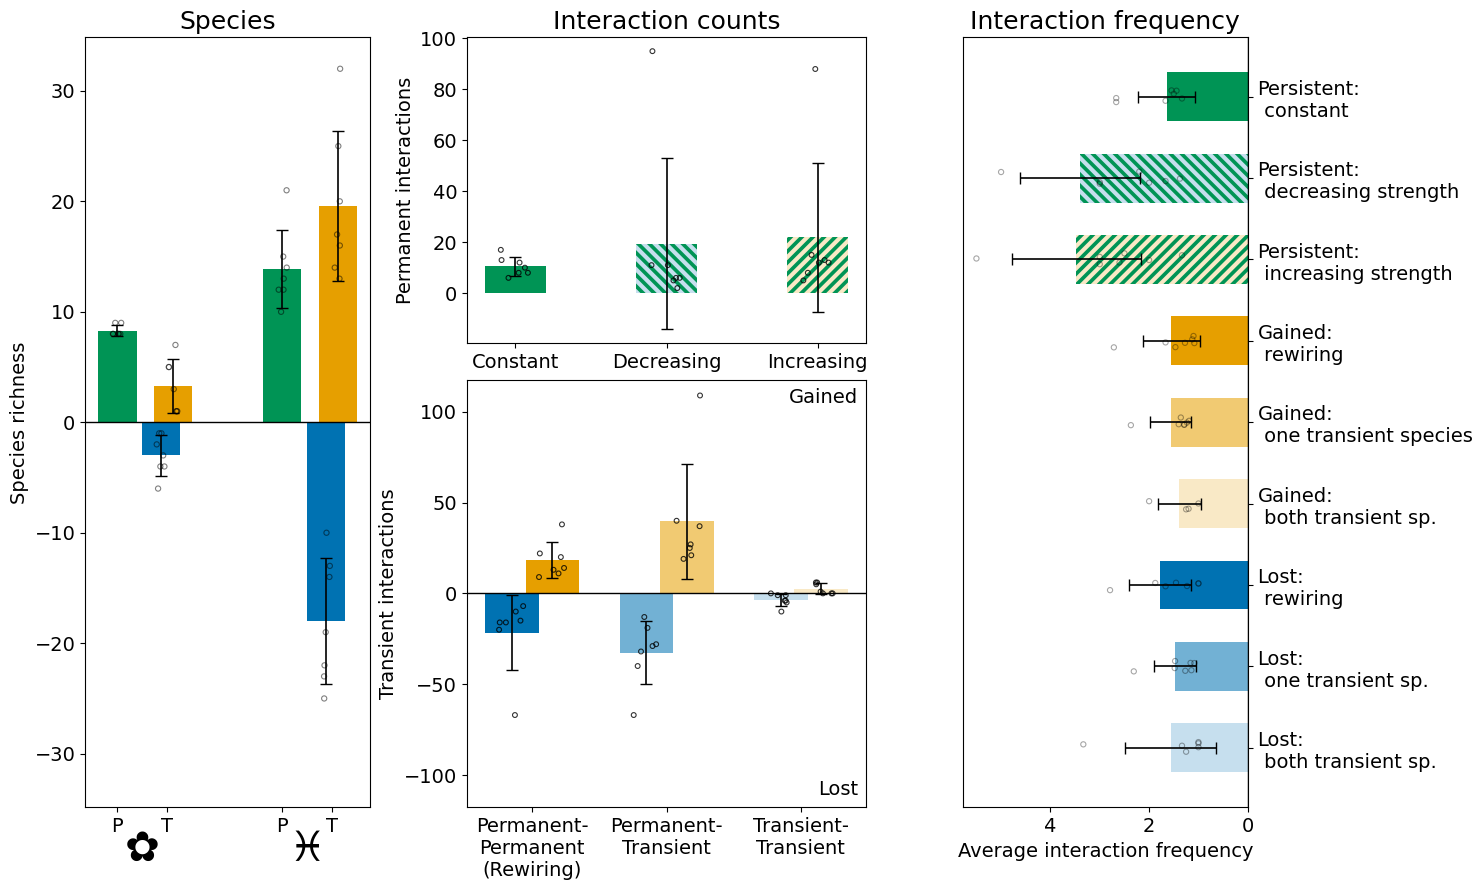

In [20]:
site=Sites[0] 
fig, (ax_species, ax_int_top, ax_int_bottom, ax_freq) = plot_species_and_interactions_summary(
    Nodes_df.loc[site],   # tu tabla de especies, filtrada al sitio
    Changes_df.loc[site],        # tu tabla de interacciones, filtrada al sitio
    figsize=(15, 10),
    species_kwargs={'value_col': 'n_nodes'},
    interactions_kwargs={'value_col': 'freq_interactions'},
    frequency_kwargs={'freq_col': 'freq_interactions', 'n_col': 'n_interactions'}
)
plt.savefig("composite.png", dpi=150, bbox_inches='tight')

In [9]:
#print(Changes_df.loc[site])
kw_result, posthoc_df = test_interaction_frequency_differences(Changes_df.loc[site])

Kruskal-Wallis: H=21.314, p=0.0064 (SIGNIFICATIVO a alpha=0.05)

Post-hoc de Dunn (p-valores, correccion Holm/Bonferroni):
        CN_CI   CN_DI   CN_II   CN_LI   CN_GI  L1N_LI  LBN_LI  G1N_GI  GBN_GI
CN_CI     1.0  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
CN_DI     1.0  1.0000  1.0000  0.8538  0.5121  0.4296  0.1539  0.6093  0.4410
CN_II     1.0  1.0000  1.0000  0.5831  0.3559  0.2818  0.0909  0.4341  0.3258
CN_LI     1.0  0.8538  0.5831  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
CN_GI     1.0  0.5121  0.3559  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
L1N_LI    1.0  0.4296  0.2818  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
LBN_LI    1.0  0.1539  0.0909  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
G1N_GI    1.0  0.6093  0.4341  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
GBN_GI    1.0  0.4410  0.3258  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000


In [10]:
kw_result, posthoc_df, latex_table = test_interaction_frequency_differences2(Changes_df.loc[site], label_dict=label_dict2)
with open("freq_int_table.tex", "w") as f:
    f.write(latex_table)

Kruskal-Wallis: H=21.314, p=0.0064 (SIGNIFICATIVO a alpha=0.05)

Post-hoc de Dunn (p-valores, correccion holm):
        CN_CI   CN_DI   CN_II   CN_LI   CN_GI  L1N_LI  LBN_LI  G1N_GI  GBN_GI
CN_CI     1.0  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
CN_DI     1.0  1.0000  1.0000  0.8538  0.5121  0.4296  0.1539  0.6093  0.4410
CN_II     1.0  1.0000  1.0000  0.5831  0.3559  0.2818  0.0909  0.4341  0.3258
CN_LI     1.0  0.8538  0.5831  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
CN_GI     1.0  0.5121  0.3559  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
L1N_LI    1.0  0.4296  0.2818  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
LBN_LI    1.0  0.1539  0.0909  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
G1N_GI    1.0  0.6093  0.4341  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
GBN_GI    1.0  0.4410  0.3258  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000

Tabla LaTeX:
\begin{table}[ht]
\centering
\begin{tabular}{lccccccccc}
\toprule
 & Persistent:
 constant & P

In [24]:
Changes_df.loc[site].reset_index().groupby("metric").mean(numeric_only=True)

,year,n_interactions,freq_interactions
metric,,,
CN_CI,2019.0,6.428571,10.571429
CN_DI,2019.0,5.714286,19.428571
CN_GI,2019.0,11.714286,18.142857
CN_II,2019.0,6.285714,21.857143
CN_LI,2019.0,12.142857,21.571429
G1N_GI,2019.0,25.428571,39.714286
GBN_GI,2019.0,1.857143,2.571429
L1N_LI,2019.0,22.142857,32.571429
LBN_LI,2019.0,2.285714,3.571429


# detail in time, for one site

/home/gato/ownCloud/Trabajo/colaboraciones/Rewiring Alfonso/Rwiring_manuscript_code/Functions.py:1379: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


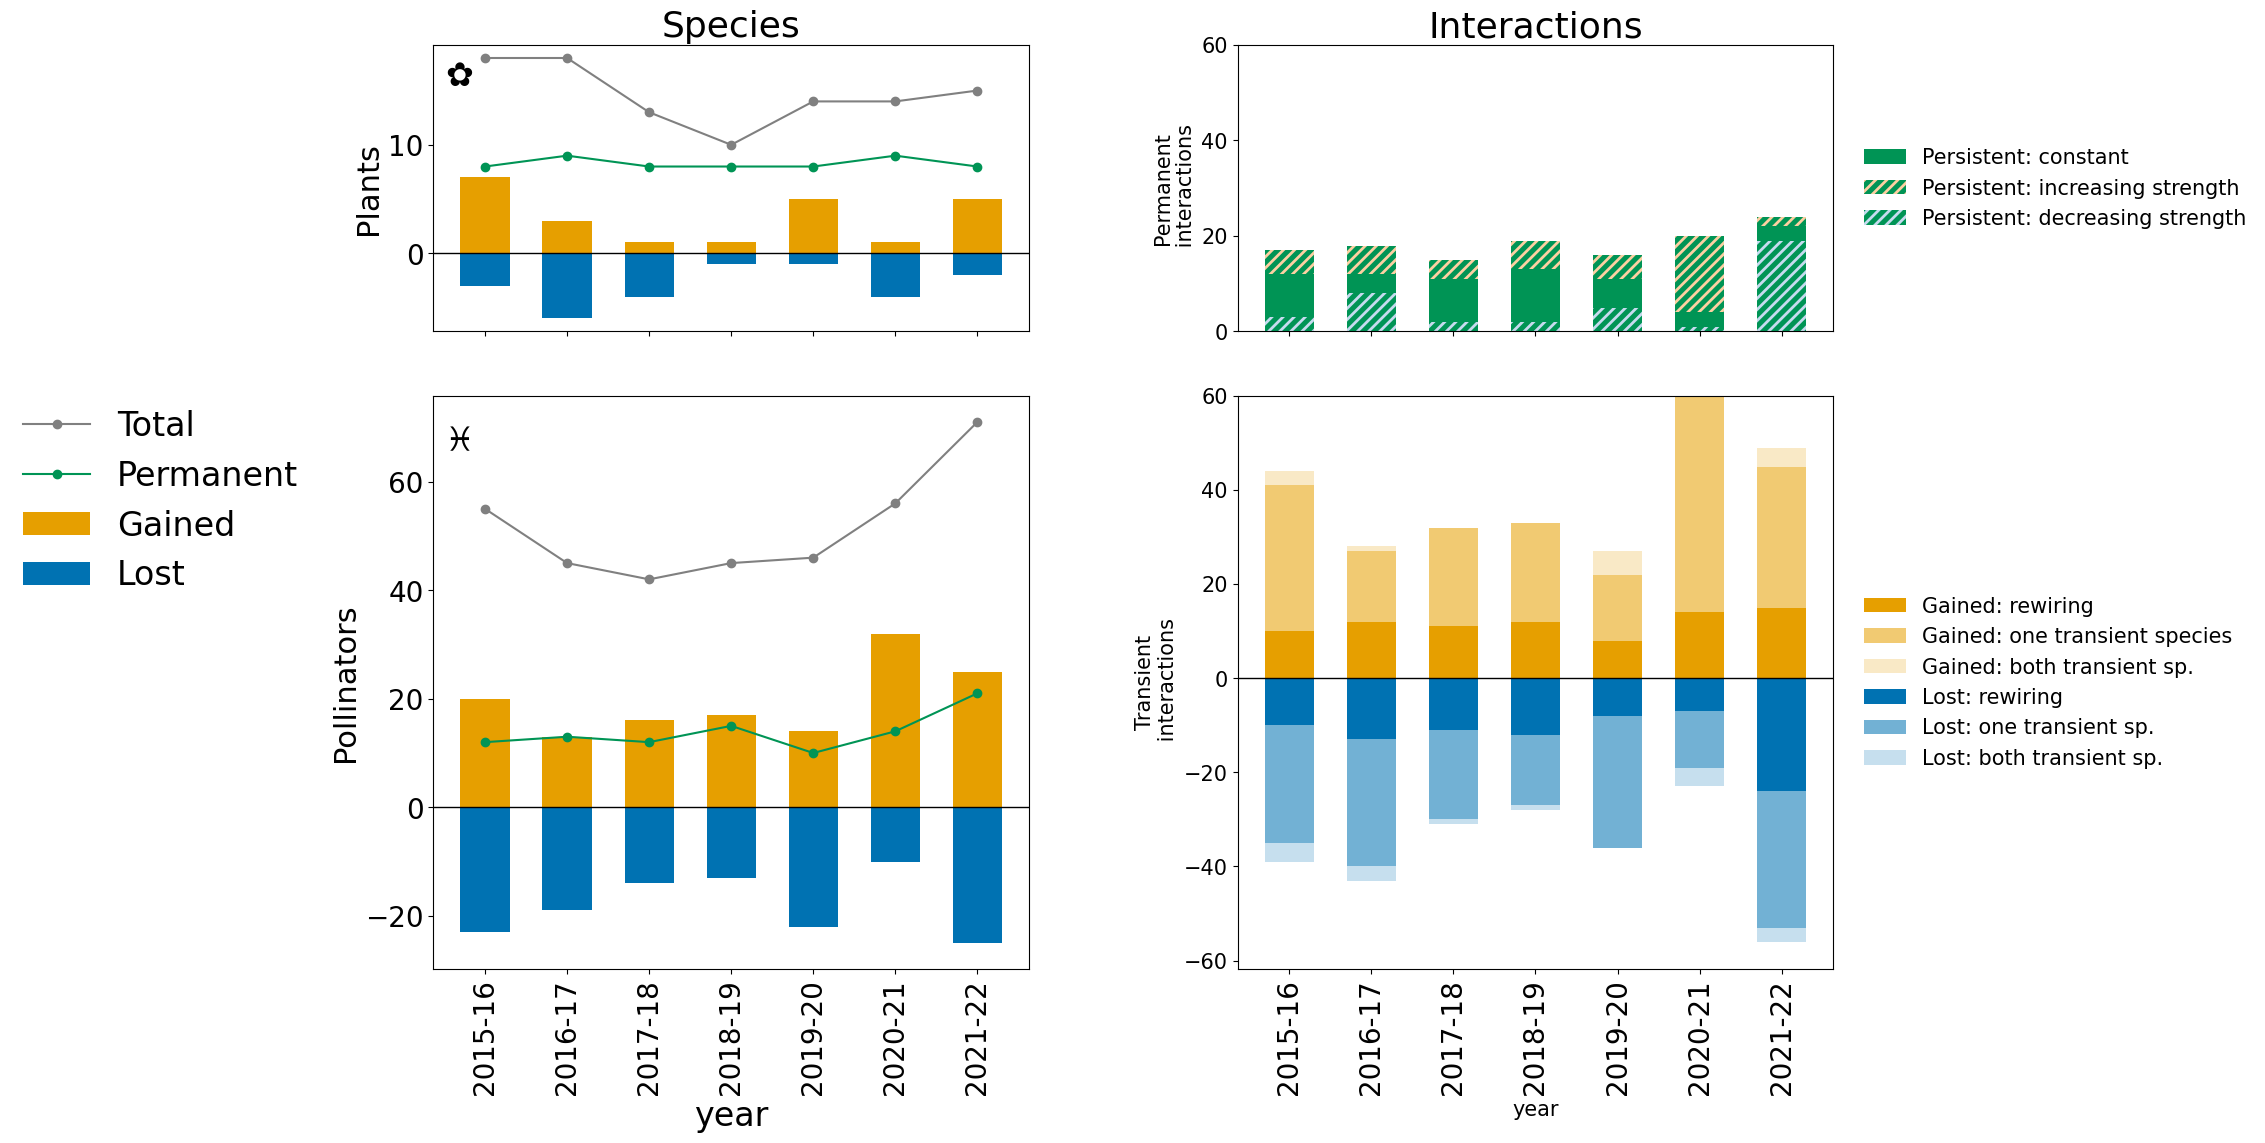

In [11]:
fig, (ax_plants, ax_poll, ax_top, ax_bottom) = plot_species_and_turnover_summary(
    Nodes_df.loc[site],        # species 
    Changes_df.loc[site], # Changes_df del sitio
)
plt.show()

## Detail in time for all sites

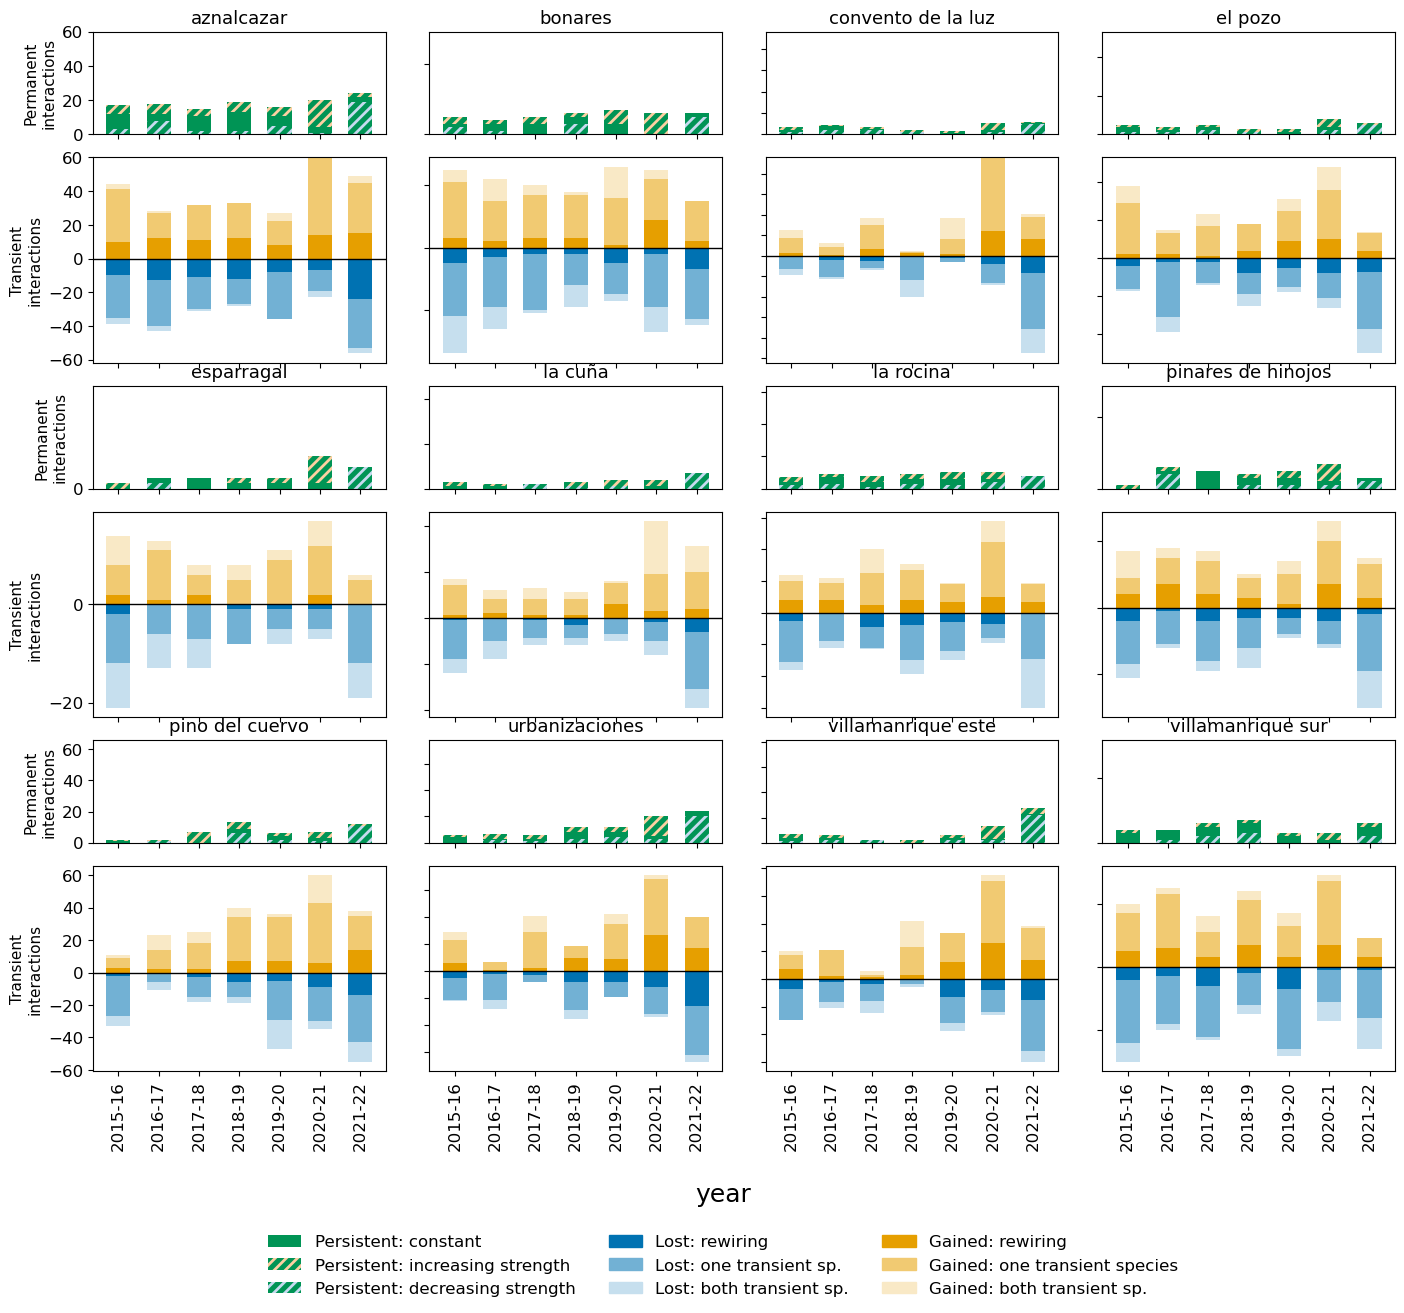

In [12]:
fig, site_axes = plot_diverging_bars_with_constant_all_sites(Changes_df, value_col='n_interactions', sharey=False, year_label_dict=year_label_dict, label_dict=label_dict)
plt.show()

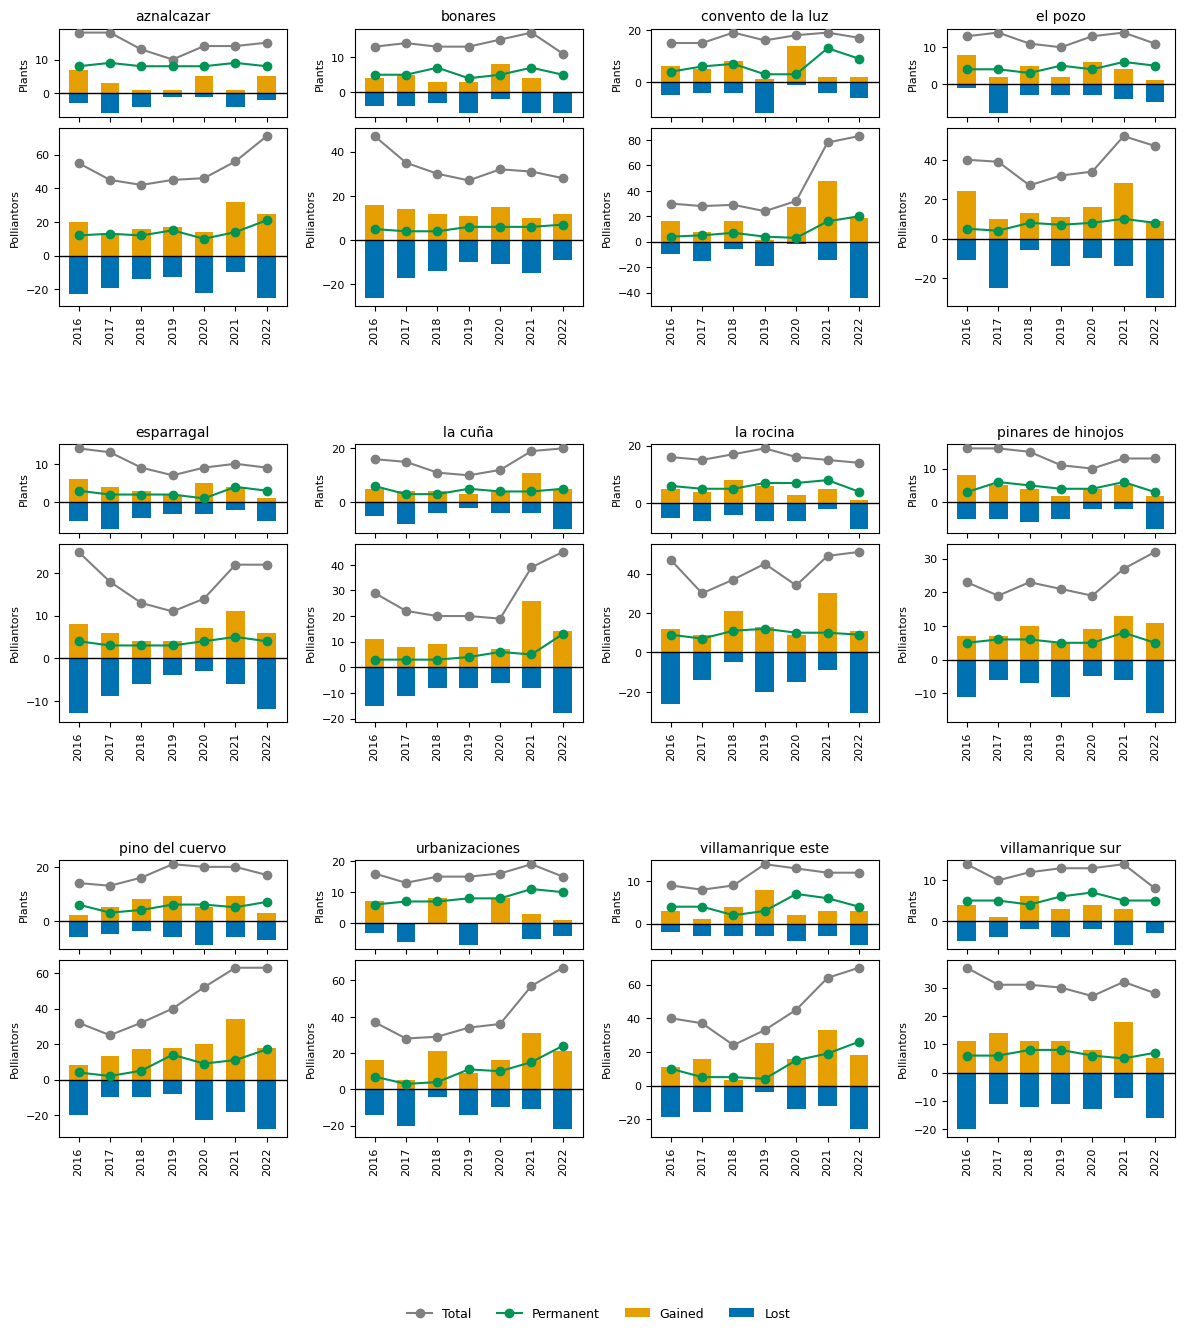

In [13]:
fig, site_axes = plot_species_turnover_all_sites(Nodes_df)
plt.savefig("species_turnover_grid.png", dpi=150, bbox_inches='tight')

# Aggregated over time for each site

# Aggregated over time for all sites

/home/gato/ownCloud/Trabajo/colaboraciones/Rewiring Alfonso/Rwiring_manuscript_code/Functions.py:2239: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


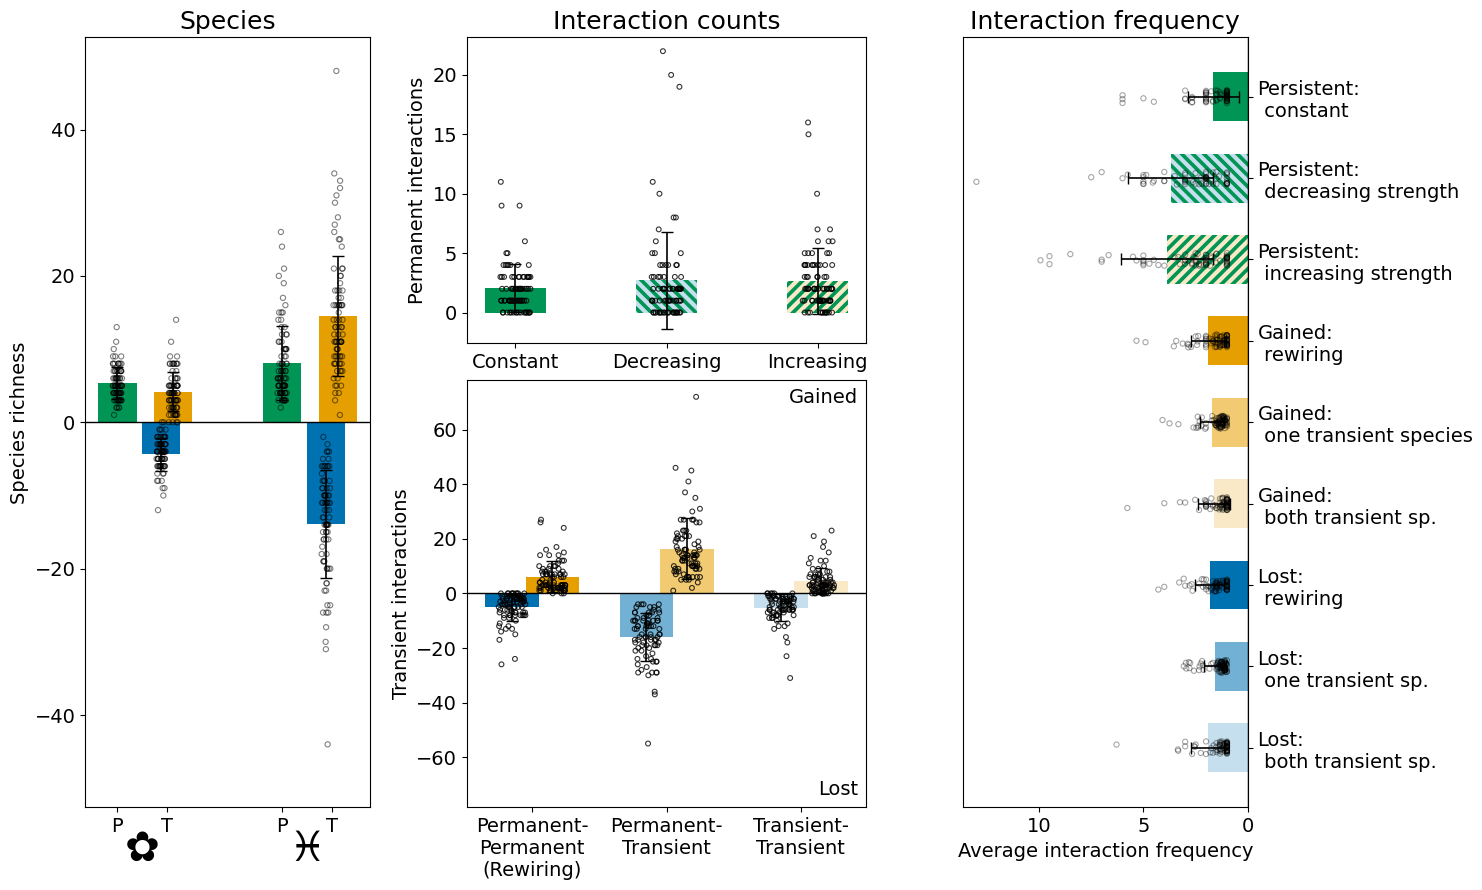

In [14]:
fig, (ax_species, ax_int_top, ax_int_bottom, ax_freq) = plot_species_and_interactions_summary(
    Nodes_df,#.loc[site],   # tu tabla de especies, filtrada al sitio
    Changes_df,#.loc[site],        # tu tabla de interacciones, filtrada al sitio
    figsize=(15, 10),
    species_kwargs={'value_col': 'n_nodes'},
    interactions_kwargs={'value_col': 'n_interactions'},
    frequency_kwargs={'freq_col': 'freq_interactions', 'n_col': 'n_interactions'}
)
plt.savefig("composite_allnet.png", dpi=150, bbox_inches='tight')

# Temporality
Ahora vamos a generar varias bases de datos de cambios, comparando las redes con lag 1 como antes, con las 2, 3 y 4

In [15]:
#Generamos los diccionaros con las 4 dataframes
#metric=['CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']
#metric_N=["PA","PP","A1","P1","A2","P2"]
#mi2=pd.MultiIndex.from_product([Sites,Years[1::],metric],names=["Site_ID", "year","metric"])
#mi2N=pd.MultiIndex.from_product([Sites,Years[1::],metric_N],names=["Site_ID", "year","metric"])
All_Changes={}
All_Nodes={}
for N in range(1,5):
    Changes_df=pd.DataFrame(index=mi2,columns=["n_interactions","freq_interactions"])
    Changes_df.sort_index(inplace=True)
    
    Nodes_df=pd.DataFrame(index=mi2N,columns=["n_nodes"])
    Nodes_df.sort_index(inplace=True)
    
    for site in Sites:
        for year in Years[0:-N]:
            changes, nodes = rewiring_freq_py(networks[site][year], networks[site][year+N])
            changes = changes.set_index('metric')          # <- AÑADIR esto
            nodes = nodes.set_index('metric')          # <- AÑADIR esto
            for m in changes.index:                        # <- 'm', NO 'metric'
                Changes_df.loc[(site, year+N, m), 'n_interactions'] = changes.loc[m, 'n_interactions']
                Changes_df.loc[(site, year+N, m), 'freq_interactions'] = changes.loc[m, 'freq_sum']
            for m in nodes.index:                        # <- 'm', NO 'metric'
                Nodes_df.loc[(site, year+N, m), 'n_nodes'] = nodes.loc[m, 'n_species']

    All_Changes[N]=Changes_df
    All_Nodes[N]=Nodes_df
  

## one site

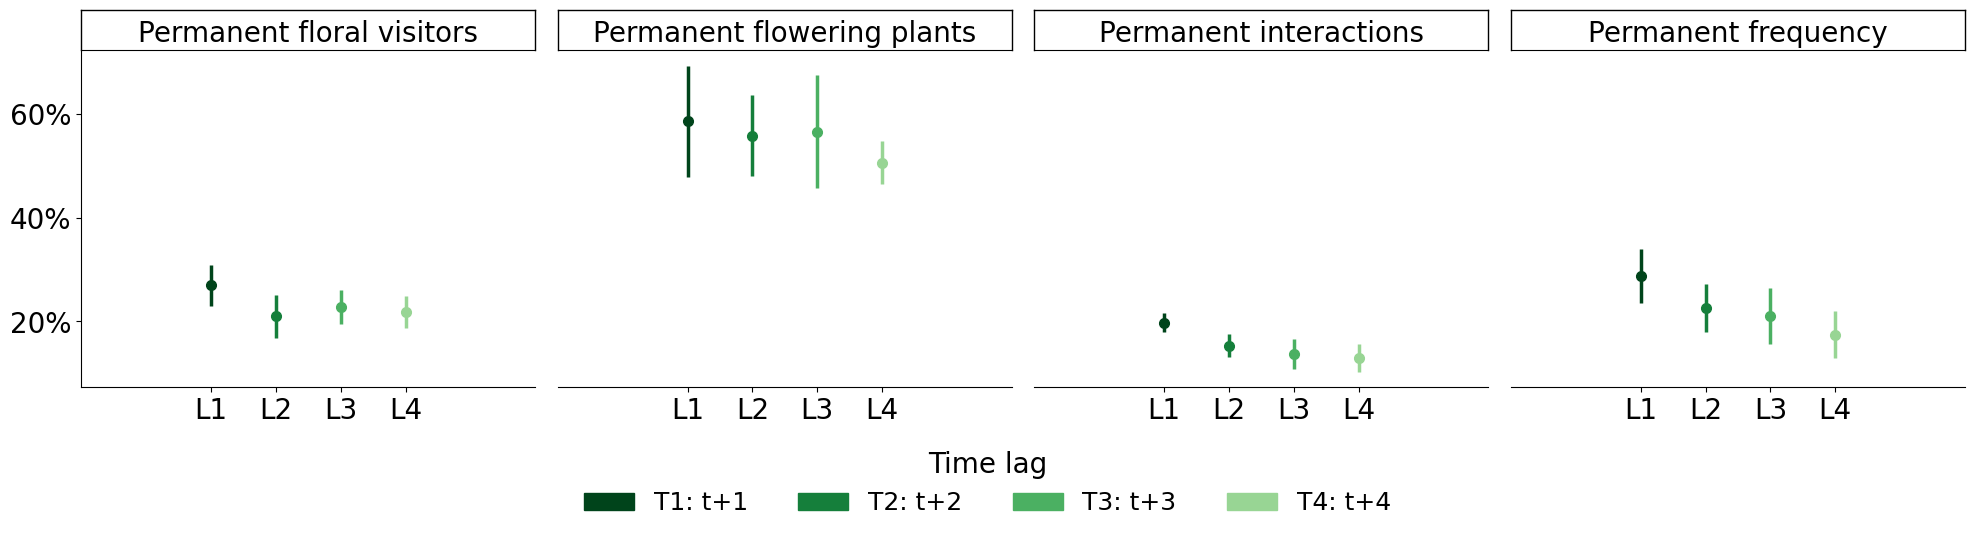

In [16]:
fig, axes, summary_df = plot_lag_summary_temporal(All_Nodes, All_Changes, site=Sites[0])
plt.savefig("temporal_diff.png", dpi=150, bbox_inches='tight')

## All sites

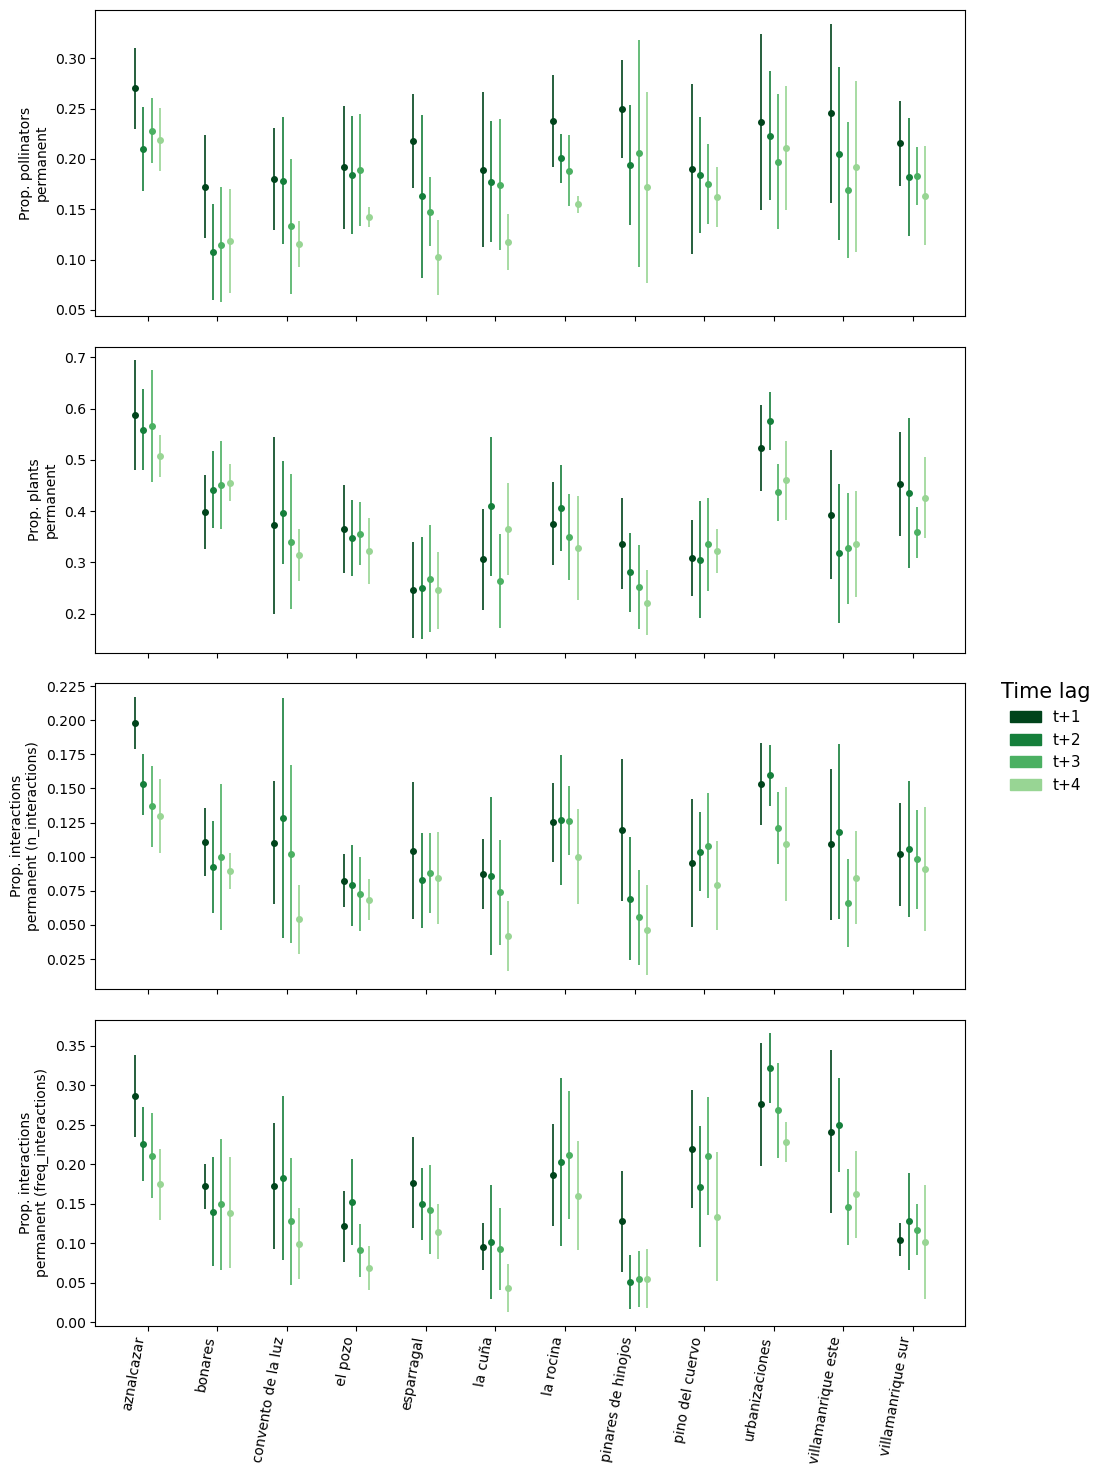

In [17]:
fig, axes, extra_data = plot_lag_summary_combined_vertical(All_Nodes, All_Changes,sharey=False, offset=0.12)
plt.savefig("temporal_diff_all.pdf", dpi=150, bbox_inches='tight')